# 과제 2 — ACT 정책 학습 및 실로봇 평가

**과제 내용**: 과제 1에서 수집한 데이터셋으로 ACT 정책을 학습하고, 실제 로봇에서 10회 평가해 성공률을 측정한 뒤, 학습된 정책을 Huggingface Hub에 업로드한다.

### 실습 환경 — **LeRobot 0.6.0**
- Python 3.12 이상, PyTorch 2.7 이상이 필요하다.
- 실습 PC에는 `lerobot[all]==0.6.0`이 설치되어 있다. 개인 PC에서 하려면 같은 버전으로 설치한다.
  ```bash
  pip install "lerobot[all]==0.6.0"
  ```
  `all`에는 학습(wandb), 녹화·텔레오퍼레이션, SO-101 모터(feetech), Diffusion Policy, SmolVLA에 필요한 패키지가 모두 들어 있다. (0.6.0부터 extra 없이 `pip install lerobot`만 하면 학습·데이터셋 의존성이 빠지므로 주의)
- 0.6.0부터 **정책을 실로봇에서 돌리는 기능이 `lerobot-record`에서 `lerobot-rollout`으로 옮겨졌다.** 평가는 반드시 `lerobot-rollout`으로 한다(2-1 참고).

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1과 같은 저장소, assignments 폴더)에 `assignment_2.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`를 추가할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [18]:
# [작성] 본인 정보로 수정
STUDENT_ID = "2021136100"
NAME = "이준"
HF_USER = "LeeJun12"

TASK = "Pick up the cube and put it in the box."   # 과제 1에서 녹화 시 사용한 영어 task 문장 그대로

TRAIN_DATASET = f"{HF_USER}/pick-cube-2cam_20261028_193431"       # 과제 1 학습 데이터셋 -> 데이터셋은 바꿔도 됨. (0.6.0의 lerobot-record로 녹화했다면 끝에 녹화 시각이 붙어 있다)
POLICY_REPO   = f"{HF_USER}/act_pick-cube-2cam" # 업로드한 ACT 정책
# 평가 녹화 데이터셋 — lerobot-rollout은 이름이 rollout_로 시작해야 하고, 끝에 녹화 시각(_YYYYMMDD_HHMMSS)을 자동으로 붙인다.
# 터미널 로그나 Hub에 실제로 올라간 이름을 그대로 적을 것.
EVAL_DATASET  = f"{HF_USER}/rollout_act_pick-cube-2cam_20261028_222716"
WANDB_URL     = "https://wandb.ai/leejun12-korea-university-of-technology-and-education/lerobot/runs/72n0heuq"               # 사용하지 않았다면 빈 문자열

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
print("정책 모델     :", f"https://huggingface.co/{POLICY_REPO}")
print("평가 데이터셋 :", f"https://huggingface.co/datasets/{EVAL_DATASET}")
print("wandb         :", WANDB_URL or "(미사용)")

학번/이름     : 2021136100 이준
태스크        : Pick up the cube and put it in the box.
학습 데이터셋 : https://huggingface.co/datasets/LeeJun12/pick-cube-2cam_20261028_193431
정책 모델     : https://huggingface.co/LeeJun12/act_pick-cube-2cam
평가 데이터셋 : https://huggingface.co/datasets/LeeJun12/rollout_act_pick-cube-2cam_20261028_222716
wandb         : https://wandb.ai/leejun12-korea-university-of-technology-and-education/lerobot/runs/72n0heuq


In [20]:
# LeRobot 버전 확인 — 학습·평가에 사용한 환경과 같은 커널에서 실행할 것
from importlib.metadata import version, PackageNotFoundError
try:
    LEROBOT_VERSION = version("lerobot")
except PackageNotFoundError:
    LEROBOT_VERSION = None
print("lerobot 버전:", LEROBOT_VERSION or "(이 커널에 설치되어 있지 않음)")
print("버전 확인   :", "통과" if LEROBOT_VERSION and LEROBOT_VERSION.startswith("0.6.") else "0.6.x가 아님 — 실습 환경을 확인할 것")

lerobot 버전: 0.6.2
버전 확인   : 통과


→ 과제 1의 데이터셋을 반드시 사용하지 않아도 됨.

In [23]:
# Hub 접근 확인 — 세 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset"), (POLICY_REPO, "model"), (EVAL_DATASET, "dataset")]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

OK   [dataset] LeeJun12/pick-cube-2cam_20261028_193431  (파일 10개)
OK   [model  ] LeeJun12/act_pick-cube-2cam  (파일 9개)
OK   [dataset] LeeJun12/rollout_act_pick-cube-2cam_20261028_222716  (파일 9개)


## 1. 학습 설정

### 1-1. 실행한 학습 명령어
`[작성]` 실제로 실행한 `lerobot-train` 명령어 전체를 아래 코드 블록에 붙여 넣는다.

```bash
lerobot-train \
  --dataset.repo_id=LeeJun12/pick-cube-2cam_20261028_193431 \
  --policy.type=act \
  --policy.device=cuda \
  --policy.repo_id=LeeJun12/act_pick-cube-2cam \
  --policy.private=false \
  --output_dir=/home/work/RobotAI/outputs/train/act_pick-cube-2cam \
  --job_name=act_pick-cube-2cam \
  --batch_size=8 --steps=100000 --save_freq=10000 --log_freq=200 \
  --num_workers=2 \
  --wandb.enable=true --wandb.disable_artifact=true

# 20,000 스텝 체크포인트에서 steps를 50,000으로 줄여 이어서 학습
lerobot-train \
  --config_path=/home/work/RobotAI/outputs/train/act_pick-cube-2cam/checkpoints/last/pretrained_model/train_config.json \
  --resume=true --steps=50000
```

> 참고 (0.6.0)
> - `--policy.repo_id`를 주면 학습이 끝난 뒤 정책이 Hub에 자동 업로드된다. 업로드하지 않으려면 `--policy.push_to_hub=false`를 주고, 나중에 `hf upload <repo_id> outputs/train/<job>/checkpoints/last/pretrained_model`로 올린다.
> - wandb를 쓰려면 `--wandb.enable=true`를 추가하고 미리 `wandb login`을 해 둔다.
> - 이전 버전 자료의 `--eval_freq`는 `--env_eval_freq`로 이름이 바뀌었다(실로봇 학습에서는 쓰지 않는다).
> - 학습 기본값: `steps=100000`, `batch_size=8`, `save_freq=20000`.

### 1-2. 학습 환경
`[작성]`
- GPU:CUDA GPU, 21566 MiB
- 학습 step 수: 50,000
- 소요 시간:1시간12분
- 기본값에서 변경한 하이퍼파라미터와 이유 (없으면 "없음"):
* steps=50000 (기본 100000): 처음에는 기본값 100,000으로 학습을 시작했다. loss가 초반 1,000 스텝 안에 6.7에서 2.2 수준으로 빠르게 떨어졌고, 약 18,000 스텝에서 0.14까지 내려온 뒤로는 감소 폭이 크게 줄었다. 이 추세로 보아 50,000 스텝(약 27 epoch)이면 충분히 수렴한다고 판단해, 20,000 스텝 체크포인트에서 --resume=true --- steps=50000으로 이어서 학습했다. ACT 기본 설정은 학습률이 1e-5로 고정(스케줄러 없음)이라, 중간에 총 스텝 수를 줄여도 그 전까지의 학습 조건은 동일하다.
* save_freq=10000 (기본 20000): 중단 시 이어서 학습할 체크포인트를 촘촘히 남기기 위해
* num_workers=<값> (기본 4): 서버 CPU 코어 수에 맞춰 데이터 로딩 속도를 확보하기 위해
* wandb.disable_artifact=true: 모델 가중치를 wandb에 중복 업로드하지 않기 위해 (가중치는 Hugging Face Hub에만 저장)
그 외 모델 구조, 학습률, batch size 등 ACT 정책 하이퍼파라미터는 기본값 그대로

In [26]:
# 업로드된 정책의 설정 확인
def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{filename} 불러오기 실패: {type(e).__name__}")
        return None

policy_cfg = load_json(POLICY_REPO, "config.json")
if policy_cfg:
    print("== 정책 설정 (config.json) ==")
    for k in ["type", "chunk_size", "n_action_steps", "n_obs_steps",
              "vision_backbone", "dim_model", "use_vae", "kl_weight", "optimizer_lr"]:
        if k in policy_cfg:
            print(f"{k:16}: {policy_cfg[k]}")

train_cfg = load_json(POLICY_REPO, "train_config.json")
if train_cfg:
    print("\n== 학습 설정 (train_config.json) ==")
    print("dataset   :", train_cfg.get("dataset", {}).get("repo_id"))
    for k in ["steps", "batch_size", "seed"]:
        if k in train_cfg:
            print(f"{k:10}: {train_cfg[k]}")

== 정책 설정 (config.json) ==
type            : act
chunk_size      : 100
n_action_steps  : 100
n_obs_steps     : 1
vision_backbone : resnet18
dim_model       : 512
use_vae         : True
kl_weight       : 10.0
optimizer_lr    : 1e-05

== 학습 설정 (train_config.json) ==
dataset   : LeeJun12/pick-cube-2cam_20261028_193431
steps     : 50000
batch_size: 8
seed      : 1000


### 1-3. 학습 곡선
`[작성]` loss 곡선을 첨부한다. wandb 화면을 캡처해 저장소의 `images/loss_curve.png`로 올리거나, 아래 코드 셀로 직접 그린다.

![loss curve](images/loss_curve.png)

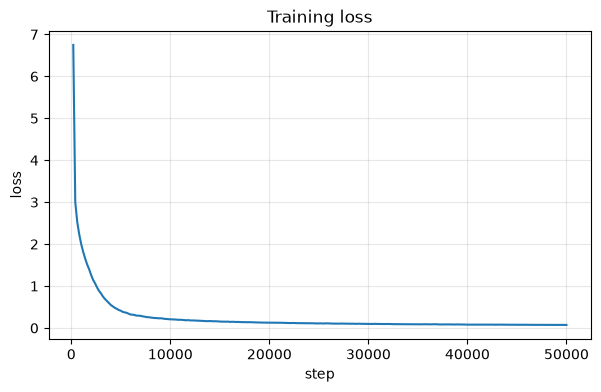

In [39]:
# (선택) wandb에서 loss를 CSV로 내보낸 경우 직접 그리기
# CSV에 step 열과 loss 열이 있다고 가정 — 열 이름은 본인 파일에 맞게 수정
import os
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "images/loss_curve.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    plt.plot(df.iloc[:, 0], df.iloc[:, 1])
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss")
    plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 없음 — 위 마크다운의 이미지로 대체")

## 2. 실로봇 평가 (10회)

### 2-1. 평가 명령어
LeRobot 0.6.0에서는 `lerobot-record`가 데이터 수집 전용이 되었다. `--policy.path`를 받지 않으며, `eval_`로 시작하는 데이터셋 이름도 거부한다.
평가는 `lerobot-rollout`의 **episodic** 전략으로 한다. `lerobot-record`처럼 에피소드 단위로 녹화하고, 에피소드 사이에 리셋 시간을 둔다.

- `--strategy.type=base`는 녹화를 하지 않으므로 이 과제의 평가로 인정하지 않는다.
- `--dataset.repo_id`의 이름은 **`rollout_`로 시작**해야 한다. 실제 업로드되는 이름에는 녹화 시각이 자동으로 붙는다(예: `rollout_act_pick-cube_20261101_143000`). 이 이름을 0번 셀의 `EVAL_DATASET`에 적는다.
- `--robot.id`는 캘리브레이션할 때 쓴 id, 카메라 이름(`top`, `wrist`)은 학습 데이터셋과 **같아야** 한다. 다르면 시작 단계에서 카메라 불일치 오류가 난다.
- `--dataset.single_task`는 학습 데이터셋의 task 문장과 똑같이 쓴다.
- `--teleop.*`는 선택 사항이다. 주면 리셋 시간 동안 리더 암으로 로봇을 되돌릴 수 있고, 생략하면 로봇이 리셋 동안 제자리에 멈춰 있다.
- 키보드: `→` 현재 에피소드 조기 종료, `←` 현재 에피소드 폐기 후 다시 녹화, `ESC` 세션 종료.
  (`←`로 다시 녹화한 회차는 2-2의 결과와 3절 고찰에 그 사실과 이유를 적는다.)

`[작성]` 평가에 실제로 사용한 `lerobot-rollout` 명령어 전체를 아래 코드 블록에 붙여 넣는다.

```bash
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=LeeJun12/act_pick-cube-2cam \
  --robot.type=so101_follower \
  --robot.port=COM4 \
  --robot.id=my_follower_arm \
  --robot.cameras="{ wrist: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 30}, overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}}" \
  --teleop.type=so101_leader \
  --teleop.port=COM5 \
  --teleop.id=my_leader_arm \
  --dataset.repo_id=LeeJun12/rollout_act_pick-cube-2cam \
  --dataset.single_task="Pick up the cube and put it in the box." \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=20 \
  --dataset.reset_time_s=15 \
  --dataset.private=false
```


In [45]:
# 평가 데이터셋 메타데이터 확인 — 에피소드 수가 10이어야 한다
info = load_json(EVAL_DATASET, "meta/info.json", repo_type="dataset")
if info:
    n_ep = info.get("total_episodes")
    print("평가 에피소드 수:", n_ep)
    print("총 프레임 수    :", info.get("total_frames"))
    print("fps             :", info.get("fps"))
    print("카메라          :", [k for k in info.get("features", {}) if k.startswith("observation.images")])
    print("\n에피소드 수 확인:", "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")

eval_name = EVAL_DATASET.split("/", 1)[-1]
print("이름 규칙 확인  :", "통과" if eval_name.startswith("rollout_") else "rollout_로 시작하지 않음 — lerobot-rollout으로 녹화했는지 확인")

평가 에피소드 수: 10
총 프레임 수    : 5630
fps             : 30
카메라          : ['observation.images.wrist', 'observation.images.overhead']

에피소드 수 확인: 통과
이름 규칙 확인  : 통과


### 2-2. 회차별 결과
`[작성]` 아래 코드 셀의 `results`를 실제 결과로 채운다. 실패한 경우 원인을 구체적으로 적는다.
(예: "큐브 위치를 놓침", "잡았으나 이동 중 떨어뜨림", "상자 가장자리에 걸림")

In [55]:
results = [
    # episode: 평가 데이터셋의 에피소드 번호, success: True/False, note: 관찰 내용 또는 실패 원인
    {"episode": 0, "success": True,  "note": ""},
    {"episode": 1, "success": True, "note": ""},
    {"episode": 2, "success": True,  "note": ""},
    {"episode": 3, "success": False,  "note": "파지를 빗겨서 한다."},
    {"episode": 4, "success": False, "note": "파지를 엉뚱한데다 한다."},
    {"episode": 5, "success": True,  "note": ""},
    {"episode": 6, "success": True,  "note": ""},
    {"episode": 7, "success": True,  "note": ""},
    {"episode": 8, "success": True,  "note": ""},
    {"episode": 9, "success": False,  "note": "접시에서 거리가 너무 멀다"},
]

res_df = pd.DataFrame(results)
n_success = int(res_df["success"].sum())
print(f"성공률: {n_success}/{len(res_df)} = {n_success/len(res_df)*100:.0f}%")
res_df

성공률: 7/10 = 70%


,episode,success,note
0,0,True,
1,1,True,
2,2,True,
3,3,False,파지를 빗겨서 한다.
4,4,False,파지를 엉뚱한데다 한다.
5,5,True,
6,6,True,
7,7,True,
8,8,True,
9,9,False,접시에서 거리가 너무 멀다


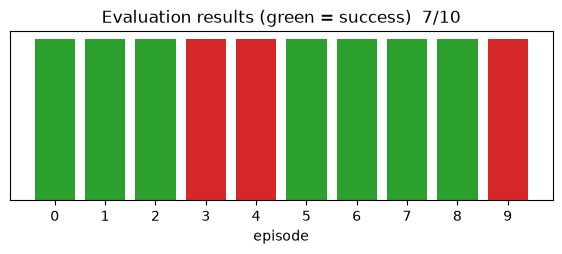

In [57]:
# 회차별 결과 시각화
colors = ["tab:green" if s else "tab:red" for s in res_df["success"]]
plt.figure(figsize=(7, 2.2))
plt.bar(res_df["episode"].astype(str), [1]*len(res_df), color=colors)
plt.yticks([]); plt.xlabel("episode")
plt.title(f"Evaluation results (green = success)  {n_success}/{len(res_df)}")
plt.show()

### 2-3. 평가 영상
`[작성]` 웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 평가 데이터셋 repo_id를 넣어 재생되는지 확인한다.
대표 성공 장면과 실패 장면을 GIF로 만들어 `images/`에 올리고 아래에 삽입한다.

![success](images/success.gif)
![failure](images/failure.gif)

## 3. 고찰
`[작성]` 각 질문에 3~5문장으로 답한다.

**3-1. 실패 원인 분석** — 실패한 회차들에 공통된 패턴이 있었는가? 정책의 어떤 한계 때문이라고 생각하는가?
실패한 회차들은 공통적으로 큐브가 접시(목표 위치)에서 비교적 멀리 놓인 경우였다. 이런 배치에서는 팔이 더 멀리 뻗어야 해서, 그리퍼가 큐브 위치에 정확히 도달하지 못하거나 집은 뒤 옮기는 도중 놓치는 모습이 보였다. 행동 복제 방식의 정책은 시연 데이터에 많이 포함된 상황에서는 잘 동작하지만, 학습 데이터에 적게 등장한 위치에서는 예측 오차가 커지고 이 오차가 이어지는 동작에 누적되는 한계가 있다. 또한 ACT는 한 번 추론할 때 100스텝(약 3.3초) 분량의 행동을 묶어서 실행하므로, 그 사이 위치가 조금 어긋나도 즉시 보정하지 못한 것도 원인으로 보인다.

**3-2. 데이터와 성능의 관계** — 과제 1에서 수집한 시연의 품질(일관성, 물체 위치 다양성 등)이 결과에 어떤 영향을 주었다고 보는가?
처음에는 정면 카메라 1대로 50개 에피소드를 수집해 학습했으나, 카메라 한 대만으로는 그리퍼와 큐브의 상대 위치를 정확히 파악하기 어렵다고 판단해 위쪽 카메라와 손목 카메라 2대로 다시 설치하고 데이터셋을 새로 구축했다. 새 데이터셋은 50개 에피소드(각 10초, 총 15,000프레임)로, 손목 카메라가 파지 직전의 근접 영상을 제공해 집는 동작의 정확도를 높이는 데 도움이 되었다고 본다. 다만 녹화 과정에서 두 카메라의 이름과 실제 영상이 서로 바뀌어 저장되었기 때문에, 평가 때도 같은 방식으로 연결해야 정책이 학습 때와 같은 입력을 받을 수 있었다. 또한 실패가 큐브가 접시에서 먼 위치에 집중된 것으로 보아, 시연에서 큐브 초기 위치가 접시 근처에 몰려 있어 위치 다양성이 부족했던 것이 성능에 영향을 준 것으로 생각한다.

**3-3. 개선 아이디어** — 성공률을 높이기 위해 데이터 수집, 학습 설정, 평가 환경 중 무엇을 어떻게 바꿔 보겠는가?
이번 평가에서 그리퍼가 쥐는 힘에 따라 결과가 크게 달라지는 것을 확인했다. 종이 상자처럼 무른 물체는 너무 세게 잡으면 찌그러지고, 반대로 약하게 잡으면 옮기는 도중 놓치는 경우가 있었다. 현재 정책은 그리퍼의 목표 위치만 출력하고 힘을 직접 조절하지 않으므로, 그리퍼 모터의 전류(토크) 값을 관측 입력에 추가하거나 최대 파지 토크를 제한해 물체 재질에 맞게 힘을 조절하도록 개선해 보고 싶다. 데이터 수집 측면에서는 단단함이 다른 여러 물체로 일정한 세기의 파지 시연을 모으고, 큐브를 접시에서 먼 위치까지 고르게 배치해 위치 다양성을 늘리겠다. 또한 일부러 살짝 어긋난 상태에서 다시 성공으로 돌아오는 회복 시연을 포함해 분포 이동에 대한 강인성을 높이겠다.

## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [59]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        hf_hub_download(rid, fname, repo_type=rtype); return True
    except Exception:
        return False

check_items = {
    "LeRobot 0.6.x 환경": bool(LEROBOT_VERSION) and LEROBOT_VERSION.startswith("0.6."),
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "정책 모델 업로드됨 (config.json)": file_ok(POLICY_REPO, "config.json", "model"),
    "정책 가중치 업로드됨 (model.safetensors)": file_ok(POLICY_REPO, "model.safetensors", "model"),
    "평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)": EVAL_DATASET.split("/", 1)[-1].startswith("rollout_"),
    "평가 데이터셋 에피소드 10개": bool(info) and info.get("total_episodes") == 10,
    "회차별 결과 10개 입력": len(results) == 10,
    "실패 회차에 원인 기재": all(r["note"].strip() for r in results if not r["success"]),
}
for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] LeRobot 0.6.x 환경
[통과] 학습 데이터셋 접근 가능 (public)
[통과] 정책 모델 업로드됨 (config.json)
[통과] 정책 가중치 업로드됨 (model.safetensors)
[통과] 평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)
[통과] 평가 데이터셋 에피소드 10개
[통과] 회차별 결과 10개 입력
[통과] 실패 회차에 원인 기재

모두 통과
